In [22]:
!pip install tensorflow scikit-learn matplotlib seaborn pillow

Defaulting to user installation because normal site-packages is not writeable


In [23]:
#import libraries
import os
import shutil
import random
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from pathlib import Path
from collections import Counter

import tensorflow as tf

from tensorflow.keras import layers, models
from tensorflow.keras.applications import MobileNetV2
from tensorflow.keras.applications.mobilenet_v2 import preprocess_input

from sklearn.metrics import (
    classification_report,
    confusion_matrix
)

In [24]:

# SETTINGS


DATASET_DIR = Path("data/cat")

SPLIT_DIR = Path("data/cat_split") #will be created

IMAGE_SIZE = (224, 224)

BATCH_SIZE = 64

EPOCHS = 10

RANDOM_SEED = 42

CLASS_NAMES = [
    "aggressive",
    "happy",
    "relaxed",
    "sad"
]

IMAGE_EXTENSIONS = {
    ".jpg",
    ".jpeg",
    ".png",
    ".webp"
}

random.seed(RANDOM_SEED)
np.random.seed(RANDOM_SEED)
tf.random.set_seed(RANDOM_SEED)

print("Dataset location:", DATASET_DIR.resolve())

Dataset location: C:\Users\Jenna\FYP\pawpers\python\data\cat


In [25]:
#data checking
print("=" * 60)
print("DATASET CHECK")
print("=" * 60)

total_images = 0

for emotion in CLASS_NAMES:

    folder = DATASET_DIR / emotion

    if not folder.exists():

        print(f"Missing folder: {folder}")

        continue

    images = [
        file for file in folder.iterdir()
        if file.suffix.lower() in IMAGE_EXTENSIONS
    ]

    print(f"{emotion.capitalize():12} : {len(images)} images")

    total_images += len(images)

print("-" * 60)
print(f"Total images  : {total_images}")

DATASET CHECK
Aggressive   : 633 images
Happy        : 624 images
Relaxed      : 619 images
Sad          : 479 images
------------------------------------------------------------
Total images  : 2355


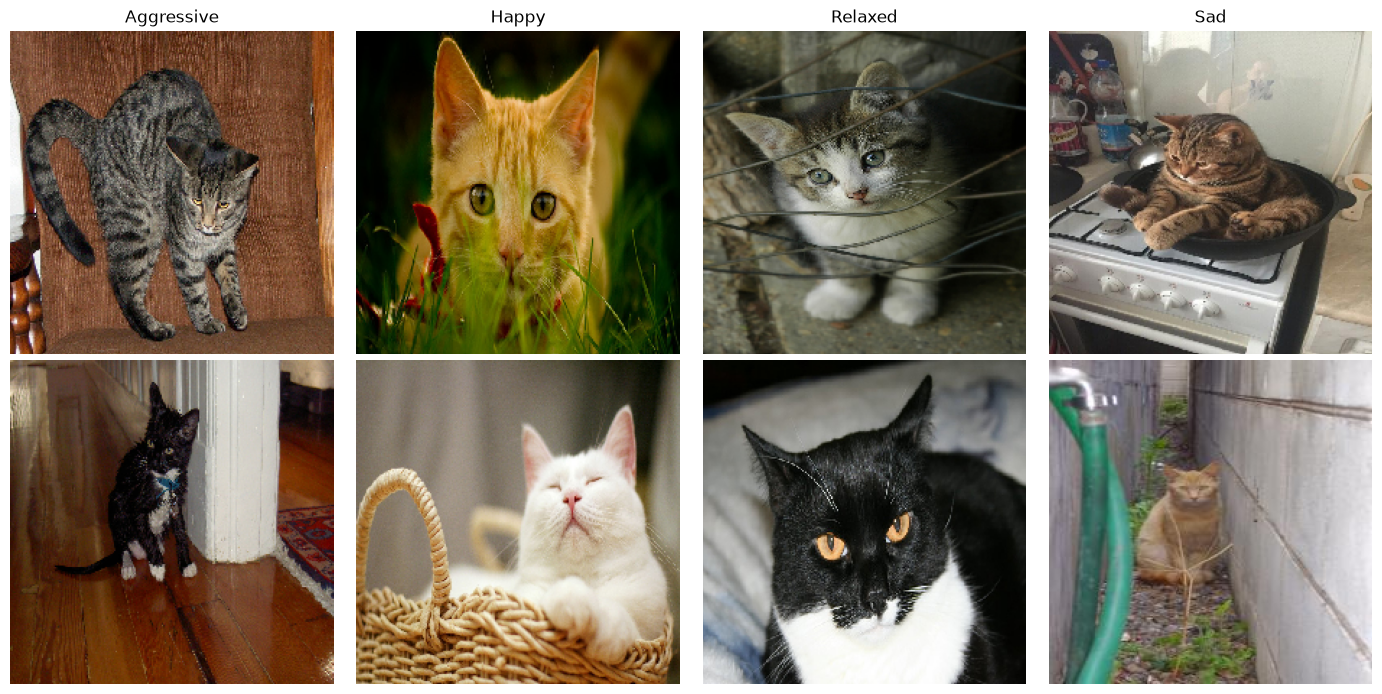

In [26]:
#display sample images
fig, axes = plt.subplots(
    2,
    4,
    figsize=(14, 7)
)

for column, emotion in enumerate(CLASS_NAMES):

    folder = DATASET_DIR / emotion

    images = [
        file for file in folder.iterdir()
        if file.suffix.lower() in IMAGE_EXTENSIONS
    ]

    sample_image = random.choice(images)

    image = tf.keras.utils.load_img(
        sample_image,
        target_size=IMAGE_SIZE
    )

    axes[0, column].imshow(image)

    axes[0, column].set_title(
        emotion.capitalize()
    )

    axes[0, column].axis("off")


    # Show another image

    sample_image = random.choice(images)

    image = tf.keras.utils.load_img(
        sample_image,
        target_size=IMAGE_SIZE
    )

    axes[1, column].imshow(image)

    axes[1, column].axis("off")


plt.tight_layout()

plt.show()

In [27]:
TRAIN_RATIO = 0.80
VALID_RATIO = 0.10
TEST_RATIO = 0.10

print(
    "Split:",
    TRAIN_RATIO,
    TRAIN_RATIO + VALID_RATIO,
    TRAIN_RATIO + VALID_RATIO + TEST_RATIO
)

Split: 0.8 0.9 1.0


In [28]:
# Remove previous split if it exists
if SPLIT_DIR.exists():

    shutil.rmtree(SPLIT_DIR)


for split in ["train", "valid", "test"]:

    for emotion in CLASS_NAMES:

        folder = SPLIT_DIR / split / emotion

        folder.mkdir(
            parents=True,
            exist_ok=True
        )


print("Split folders created.")

Split folders created.


In [29]:
for emotion in CLASS_NAMES:

    source_folder = DATASET_DIR / emotion

    images = [
        file for file in source_folder.iterdir()
        if file.suffix.lower() in IMAGE_EXTENSIONS
    ]

    random.shuffle(images)

    total = len(images)

    train_end = int(total * TRAIN_RATIO)

    valid_end = train_end + int(total * VALID_RATIO)


    train_images = images[:train_end]

    valid_images = images[train_end:valid_end]

    test_images = images[valid_end:]


    print("\n", emotion.upper())

    print("Total      :", total)

    print("Train      :", len(train_images))

    print("Validation :", len(valid_images))

    print("Test       :", len(test_images))


    # Copy files

    for image in train_images:

        shutil.copy2(
            image,
            SPLIT_DIR / "train" / emotion / image.name
        )


    for image in valid_images:

        shutil.copy2(
            image,
            SPLIT_DIR / "valid" / emotion / image.name
        )


    for image in test_images:

        shutil.copy2(
            image,
            SPLIT_DIR / "test" / emotion / image.name
        )


print("\nDataset splitting completed!")


 AGGRESSIVE
Total      : 633
Train      : 506
Validation : 63
Test       : 64



 HAPPY
Total      : 624
Train      : 499
Validation : 62
Test       : 63

 RELAXED
Total      : 619
Train      : 495
Validation : 61
Test       : 63

 SAD
Total      : 479
Train      : 383
Validation : 47
Test       : 49

Dataset splitting completed!


In [30]:
train_dataset = tf.keras.utils.image_dataset_from_directory(
    SPLIT_DIR / "train",

    image_size=IMAGE_SIZE,

    batch_size=BATCH_SIZE,

    label_mode="categorical",

    shuffle=True,

    seed=RANDOM_SEED
)


valid_dataset = tf.keras.utils.image_dataset_from_directory(
    SPLIT_DIR / "valid",

    image_size=IMAGE_SIZE,

    batch_size=BATCH_SIZE,

    label_mode="categorical",

    shuffle=False
)


test_dataset = tf.keras.utils.image_dataset_from_directory(
    SPLIT_DIR / "test",

    image_size=IMAGE_SIZE,

    batch_size=BATCH_SIZE,

    label_mode="categorical",

    shuffle=False
)

print("Class names:")
print(train_dataset.class_names)

Found 1883 files belonging to 4 classes.
Found 233 files belonging to 4 classes.
Found 239 files belonging to 4 classes.
Class names:
['aggressive', 'happy', 'relaxed', 'sad']


In [31]:
AUTOTUNE = tf.data.AUTOTUNE

train_dataset = train_dataset.prefetch(
    AUTOTUNE
)

valid_dataset = valid_dataset.prefetch(
    AUTOTUNE
)

test_dataset = test_dataset.prefetch(
    AUTOTUNE
)

In [32]:
#data augmentation
data_augmentation = tf.keras.Sequential([

    layers.RandomFlip(
        "horizontal"
    ),

    layers.RandomRotation(
        0.08
    ),

    layers.RandomZoom(
        0.10
    ),

], name="data_augmentation")

In [33]:
#PRETRAINED MODEL:
#MobileNetV2
base_model = MobileNetV2(
    input_shape=(
        IMAGE_SIZE[0],
        IMAGE_SIZE[1],
        3
    ),

    include_top=False,

    weights="imagenet"
)

print("MobileNetV2 loaded.")

MobileNetV2 loaded.


In [34]:
base_model.trainable = False

print(
    "Trainable layers:",
    sum(
        layer.trainable
        for layer in base_model.layers
    )
)

Trainable layers: 0


In [35]:
inputs = layers.Input(
    shape=(
        IMAGE_SIZE[0],
        IMAGE_SIZE[1],
        3
    )
)


# Data augmentation

x = data_augmentation(inputs)


# MobileNetV2 preprocessing

x = preprocess_input(x)


# Pretrained CNN

x = base_model(
    x,
    training=False
)


# Convert feature maps into a vector

x = layers.GlobalAveragePooling2D()(x)


# Prevent overfitting

x = layers.Dropout(
    0.3
)(x)


# Four emotion classes

outputs = layers.Dense(
    4,
    activation="softmax"
)(x)


model = models.Model(
    inputs,
    outputs
)


model.summary()

Model: "functional_3"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ input_layer_4 (InputLayer)      │ (None, 224, 224, 3)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ data_augmentation (Sequential)  │ (None, 224, 224, 3)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ true_divide_1 (TrueDivide)      │ (None, 224, 224, 3)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ subtract_1 (Subtract)           │ (None, 224, 224, 3)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ mobilenetv2_1.00_224            │ (None, 7, 7, 1280)     │     2,257,984 │
│ (Functional)                    │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ global_average_pooling2d_1      │ (None, 1280)           │             0 │
│ (GlobalAveragePooling2D)        │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_1 (Dropout)             │ (None, 1280)           │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 4)              │         5,124 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 2,263,108 (8.63 MB)

 Trainable params: 5,124 (20.02 KB)

 Non-trainable params: 2,257,984 (8.61 MB)

In [36]:
#compile
model.compile(

    optimizer=tf.keras.optimizers.Adam(
        learning_rate=0.001
    ),

    loss="categorical_crossentropy",

    metrics=[
        "accuracy"
    ]
)

In [37]:
#early stopping 
early_stopping = tf.keras.callbacks.EarlyStopping(

    monitor="val_loss",

    patience=3,

    restore_best_weights=True
)


reduce_lr = tf.keras.callbacks.ReduceLROnPlateau(

    monitor="val_loss",

    factor=0.2,

    patience=2,

    min_lr=1e-6
)

In [38]:
#train model
history = model.fit(

    train_dataset,

    validation_data=valid_dataset,

    epochs=EPOCHS,

    callbacks=[
        early_stopping,
        reduce_lr
    ]
)

Epoch 1/10
30/30 ━━━━━━━━━━━━━━━━━━━━ 46s 1s/step - accuracy: 0.3107 - loss: 1.5344 - val_accuracy: 0.3691 - val_loss: 1.3846 - learning_rate: 0.0010
Epoch 2/10
30/30 ━━━━━━━━━━━━━━━━━━━━ 34s 1s/step - accuracy: 0.3601 - loss: 1.3862 - val_accuracy: 0.4249 - val_loss: 1.2889 - learning_rate: 0.0010
Epoch 3/10
30/30 ━━━━━━━━━━━━━━━━━━━━ 35s 1s/step - accuracy: 0.4089 - loss: 1.2937 - val_accuracy: 0.4249 - val_loss: 1.2581 - learning_rate: 0.0010
Epoch 4/10
30/30 ━━━━━━━━━━━━━━━━━━━━ 34s 1s/step - accuracy: 0.4482 - loss: 1.2477 - val_accuracy: 0.4034 - val_loss: 1.2414 - learning_rate: 0.0010
Epoch 5/10
30/30 ━━━━━━━━━━━━━━━━━━━━ 34s 1s/step - accuracy: 0.4684 - loss: 1.2090 - val_accuracy: 0.4292 - val_loss: 1.3028 - learning_rate: 0.0010
Epoch 6/10
30/30 ━━━━━━━━━━━━━━━━━━━━ 35s 1s/step - accuracy: 0.4981 - loss: 1.1800 - val_accuracy: 0.4292 - val_loss: 1.2571 - learning_rate: 0.0010
Epoch 7/10
30/30 ━━━━━━━━━━━━━━━━━━━━ 36s 1s/step - accuracy: 0.5008 - loss: 1.1439 - val_accuracy: 

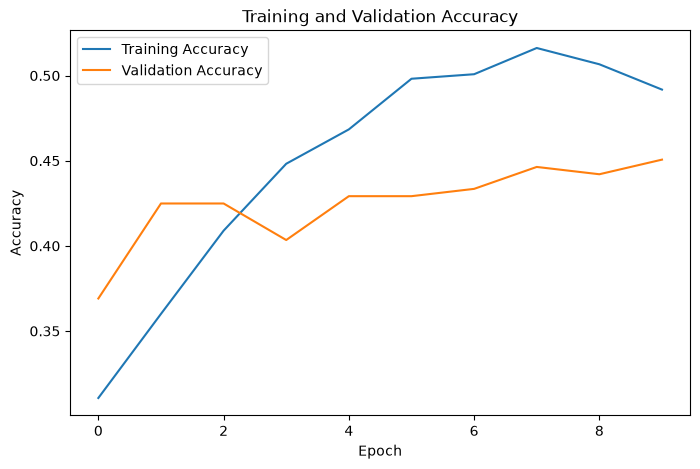

In [39]:
plt.figure(figsize=(8, 5))

plt.plot(
    history.history["accuracy"],
    label="Training Accuracy"
)

plt.plot(
    history.history["val_accuracy"],
    label="Validation Accuracy"
)

plt.title(
    "Training and Validation Accuracy"
)

plt.xlabel("Epoch")

plt.ylabel("Accuracy")

plt.legend()

plt.show()

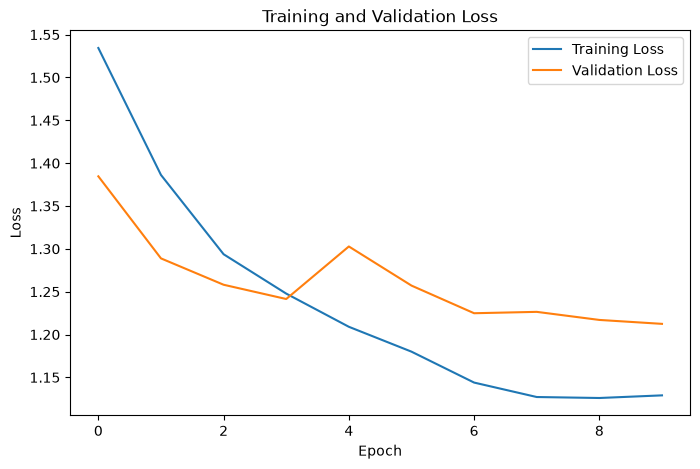

In [40]:
plt.figure(figsize=(8, 5))

plt.plot(
    history.history["loss"],
    label="Training Loss"
)

plt.plot(
    history.history["val_loss"],
    label="Validation Loss"
)

plt.title(
    "Training and Validation Loss"
)

plt.xlabel("Epoch")

plt.ylabel("Loss")

plt.legend()

plt.show()

In [41]:
#evaluate test data
test_loss, test_accuracy = model.evaluate(
    test_dataset
)

print(
    f"Test Loss: {test_loss:.4f}"
)

print(
    f"Test Accuracy: {test_accuracy:.4f}"
)

4/4 ━━━━━━━━━━━━━━━━━━━━ 4s 862ms/step - accuracy: 0.4310 - loss: 1.2457
Test Loss: 1.2457
Test Accuracy: 0.4310


In [42]:
#generate predictions
y_true = []
y_pred = []


for images, labels in test_dataset:

    predictions = model.predict(
        images,
        verbose=0
    )

    predicted_classes = np.argmax(
        predictions,
        axis=1
    )

    true_classes = np.argmax(
        labels.numpy(),
        axis=1
    )

    y_true.extend(
        true_classes
    )

    y_pred.extend(
        predicted_classes
    )


y_true = np.array(y_true)

y_pred = np.array(y_pred)

In [43]:
#classification report
print(
    classification_report(
        y_true,
        y_pred,
        target_names=CLASS_NAMES,
        digits=4
    )
)

              precision    recall  f1-score   support

  aggressive     0.5306    0.4062    0.4602        64
       happy     0.3390    0.3175    0.3279        63
     relaxed     0.3909    0.6825    0.4971        63
         sad     0.6667    0.2857    0.4000        49

    accuracy                         0.4310       239
   macro avg     0.4818    0.4230    0.4213       239
weighted avg     0.4712    0.4310    0.4227       239



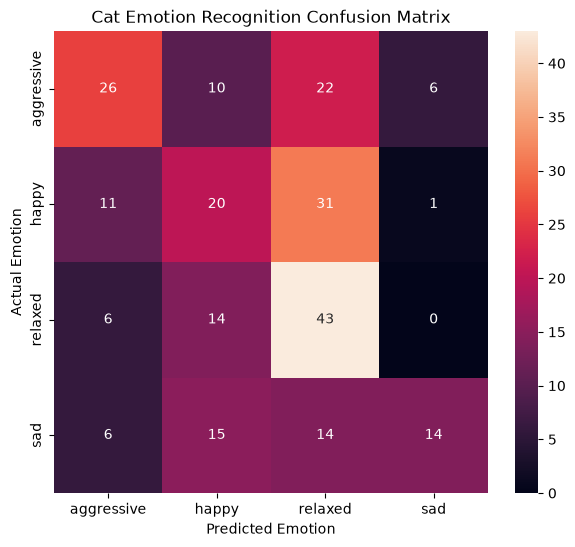

In [44]:
#confusion matrix
cm = confusion_matrix(
    y_true,
    y_pred
)


plt.figure(
    figsize=(7, 6)
)


sns.heatmap(
    cm,
    annot=True,
    fmt="d",
    xticklabels=CLASS_NAMES,
    yticklabels=CLASS_NAMES
)


plt.xlabel(
    "Predicted Emotion"
)

plt.ylabel(
    "Actual Emotion"
)

plt.title(
    "Cat Emotion Recognition Confusion Matrix"
)

plt.show()

In [47]:
def predict_emotion(image_path):

    image = tf.keras.utils.load_img(
        image_path,
        target_size=IMAGE_SIZE
    )

    image_array = tf.keras.utils.img_to_array(
        image
    )

    image_array = np.expand_dims(
        image_array,
        axis=0
    )


    predictions = model.predict(
        image_array,
        verbose=0
    )[0]


    predicted_index = np.argmax(
        predictions
    )

    predicted_emotion = CLASS_NAMES[
        predicted_index
    ]

    confidence = predictions[
        predicted_index
    ]


    plt.figure(
        figsize=(5, 5)
    )

    plt.imshow(image)

    plt.axis("off")

    plt.title(
        f"{predicted_emotion.capitalize()} "
        f"({confidence * 100:.2f}%)"
    )

    plt.show()


    print(
        f"Prediction: {predicted_emotion.capitalize()}"
    )

    print(
        f"Confidence: {confidence * 100:.2f}%"
    )


    print("\nAll probabilities:")

    for emotion, probability in zip(
        CLASS_NAMES,
        predictions
    ):

        print(
            f"{emotion.capitalize():12} "
            f"{probability * 100:.2f}%"
        )

   

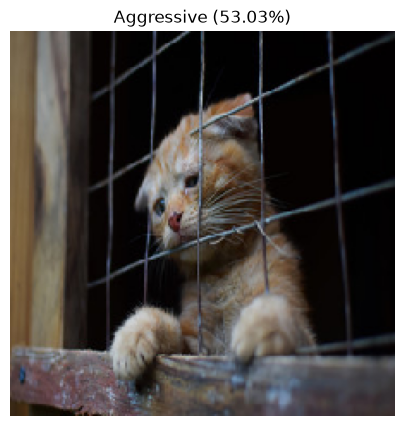

Prediction: Aggressive
Confidence: 53.03%

All probabilities:
Aggressive   53.03%
Happy        9.15%
Relaxed      13.33%
Sad          24.50%


In [51]:
predict_emotion("data/cat/Sad/593.jpg")

In [52]:
#fine tuning
base_model.trainable = True


# Freeze the earlier layers

fine_tune_from = 100


for layer in base_model.layers[
    :fine_tune_from
]:

    layer.trainable = False


print(
    "Trainable layers:",
    sum(
        layer.trainable
        for layer in base_model.layers
    )
)

Trainable layers: 54


In [53]:
#recompile
base_model.trainable = True


# Freeze the earlier layers

fine_tune_from = 100


for layer in base_model.layers[
    :fine_tune_from
]:

    layer.trainable = False


print(
    "Trainable layers:",
    sum(
        layer.trainable
        for layer in base_model.layers
    )
)

Trainable layers: 54


In [54]:
fine_tune_history = model.fit(

    train_dataset,

    validation_data=valid_dataset,

    epochs=10,

    callbacks=[
        early_stopping,
        reduce_lr
    ]
)

Epoch 1/10


C:\Users\Jenna\AppData\Roaming\Python\Python312\site-packages\keras\src\trainers\epoch_iterator.py:74: UserWarning: `shuffle=True` was passed, but will be ignored since the data `x` was provided as a tf.data.Dataset. The Dataset is expected to already be shuffled (via `.shuffle(buffer_size)`).
  self.data_adapter = data_adapters.get_data_adapter(


30/30 ━━━━━━━━━━━━━━━━━━━━ 36s 1s/step - accuracy: 0.5130 - loss: 1.0982 - val_accuracy: 0.4549 - val_loss: 1.2168 - learning_rate: 2.0000e-04
Epoch 2/10
30/30 ━━━━━━━━━━━━━━━━━━━━ 35s 1s/step - accuracy: 0.5273 - loss: 1.1163 - val_accuracy: 0.4549 - val_loss: 1.2112 - learning_rate: 2.0000e-04
Epoch 3/10
30/30 ━━━━━━━━━━━━━━━━━━━━ 36s 1s/step - accuracy: 0.5157 - loss: 1.1011 - val_accuracy: 0.4635 - val_loss: 1.2092 - learning_rate: 2.0000e-04
Epoch 4/10
30/30 ━━━━━━━━━━━━━━━━━━━━ 35s 1s/step - accuracy: 0.5231 - loss: 1.1024 - val_accuracy: 0.4549 - val_loss: 1.2113 - learning_rate: 2.0000e-04
Epoch 5/10
30/30 ━━━━━━━━━━━━━━━━━━━━ 35s 1s/step - accuracy: 0.5348 - loss: 1.0865 - val_accuracy: 0.4506 - val_loss: 1.2238 - learning_rate: 2.0000e-04
Epoch 6/10
30/30 ━━━━━━━━━━━━━━━━━━━━ 36s 1s/step - accuracy: 0.5300 - loss: 1.0856 - val_accuracy: 0.4464 - val_loss: 1.2104 - learning_rate: 4.0000e-05


In [55]:
test_loss, test_accuracy = model.evaluate(
    test_dataset
)

print(
    f"Final Test Accuracy: {test_accuracy * 100:.2f}%"
)

4/4 ━━━━━━━━━━━━━━━━━━━━ 4s 903ms/step - accuracy: 0.4226 - loss: 1.2412
Final Test Accuracy: 42.26%
